In [2]:
import torch

device = "mps" if torch.backends.mps.is_available() else "cpu"
print("torch", torch.__version__, "| device:", device)   # kỳ vọng: device: mps


torch 2.14.1 | device: mps


In [3]:
from transformers import CLIPModel, CLIPProcessor

MODEL = "openai/clip-vit-base-patch32"
model = CLIPModel.from_pretrained(MODEL).to(device).eval()
processor = CLIPProcessor.from_pretrained(MODEL)

print("Số chiều vector:", model.config.projection_dim)   # kỳ vọng: 512


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1028 14:50:48.274000 94337 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 398/398 [00:00<00:00, 15501.43it/s]
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.


Số chiều vector: 512


Đây là một bài kiểm tra nhỏ: đưa CLIP một tấm ảnh và 3 câu mô tả, hỏi nó “câu nào khớp với ảnh nhất?”. Nếu nó chọn đúng thì model hoạt động bình thường, yên tâm encode cả kho.

1.000  dogs playing in the snow
0.000  a man surfing on a wave
0.000  a child eating cake


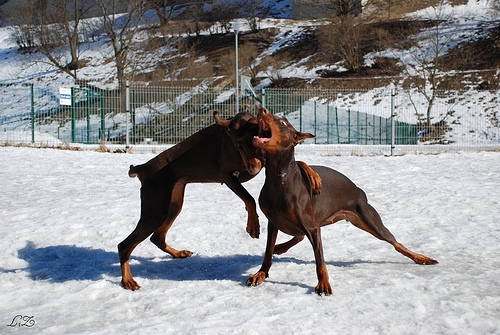

In [ ]:
from PIL import Image

img = Image.open("../data/images/test_0.jpg")
texts = ["dogs playing in the snow", "a man surfing on a wave", "a child eating cake"]

inputs = processor(text=texts, images=img, return_tensors="pt", padding=True).to(device)
with torch.no_grad():
    probs = model(**inputs).logits_per_image.softmax(dim=-1)[0]

for t, p in zip(texts, probs):
    print(f"{p:.3f}  {t}")
display(img)


In [5]:
import json
import pandas as pd

ROOT = ".."

caps = pd.read_csv(f"{ROOT}/data/captions.csv")
caps = caps[caps["split"] == "test"].reset_index(drop=True)

meta = pd.read_csv(f"{ROOT}/data/metadata.csv")
imgs = meta[meta["split"] == "test"].reset_index(drop=True)

t2i = json.load(open(f"{ROOT}/artifacts/ground_truth/t2i.json"))

print(len(caps), "caption |", len(imgs), "ảnh |", len(t2i), "đáp án")   # kỳ vọng: 4999 | 1000 | 4999
assert set(caps["image_id"]) == set(imgs["image_id"])                     # caption và ảnh khớp nhau


4999 caption | 1000 ảnh | 4999 đáp án


In [6]:
import os
import numpy as np
from tqdm.auto import tqdm

EMB = f"{ROOT}/artifacts/embeddings"
os.makedirs(EMB, exist_ok=True)
BATCH = 64

img_vecs = []
for i in tqdm(range(0, len(imgs), BATCH)):
    paths = imgs["path"].iloc[i:i + BATCH]
    batch = [Image.open(f"{ROOT}/{p}").convert("RGB") for p in paths]
    inputs = processor(images=batch, return_tensors="pt").to(device)
    with torch.no_grad():
        v = model.get_image_features(**inputs).pooler_output
    img_vecs.append(v.cpu())

img_vecs = torch.cat(img_vecs)
img_vecs = img_vecs / img_vecs.norm(dim=-1, keepdim=True)   # chuẩn hoá L2
img_vecs = img_vecs.numpy()

np.save(f"{EMB}/test_images.npy", img_vecs)
print(img_vecs.shape)                                   
print(np.linalg.norm(img_vecs, axis=1)[:3])             


100%|██████████| 16/16 [00:13<00:00,  1.18it/s]

(1000, 512)
[1.        1.0000001 0.9999999]


In [7]:
BATCH_TXT = 256

cap_vecs = []
for i in tqdm(range(0, len(caps), BATCH_TXT)):
    texts = caps["caption"].iloc[i:i + BATCH_TXT].tolist()
    inputs = processor(text=texts, return_tensors="pt", padding=True, truncation=True).to(device)
    with torch.no_grad():
        v = model.get_text_features(**inputs).pooler_output
    cap_vecs.append(v.cpu())

cap_vecs = torch.cat(cap_vecs)
cap_vecs = cap_vecs / cap_vecs.norm(dim=-1, keepdim=True)   # chuẩn hoá L2
cap_vecs = cap_vecs.numpy()

np.save(f"{EMB}/test_captions.npy", cap_vecs)
print(cap_vecs.shape)                                   # kỳ vọng: (4999, 512)
print(np.linalg.norm(cap_vecs, axis=1)[:3])             # kỳ vọng: ~1.0


100%|██████████| 20/20 [00:10<00:00,  1.99it/s]

(4999, 512)
[1.        1.        0.9999999]


In [8]:
# 1. kích thước, độ dài, NaN
assert img_vecs.shape == (1000, 512) and cap_vecs.shape == (4999, 512)
assert np.allclose(np.linalg.norm(img_vecs, axis=1), 1, atol=1e-3)
assert np.allclose(np.linalg.norm(cap_vecs, axis=1), 1, atol=1e-3)
assert not np.isnan(img_vecs).any() and not np.isnan(cap_vecs).any()

# 2. caption có gần ảnh của nó hơn ảnh khác không
img_idx = {img_id: i for i, img_id in enumerate(imgs["image_id"])}
sim = cap_vecs @ img_vecs.T
own = sim[np.arange(len(caps)), caps["image_id"].map(img_idx)]
print("Caption ↔ ảnh của nó:", own.mean().round(3), "| ↔ ảnh khác:", sim.mean().round(3))   # kỳ vọng: ~0.3 | ~0.2
print("Tỉ lệ caption có điểm với ảnh của nó > trung bình:", (own > sim.mean(axis=1)).mean().round(3))   # kỳ vọng: gần 1.0


Caption ↔ ảnh của nó: 0.317 | ↔ ảnh khác: 0.172
Tỉ lệ caption có điểm với ảnh của nó > trung bình: 1.0


In [9]:
K = 10
img_ids = imgs["image_id"].to_numpy()

sim_t2i = cap_vecs @ img_vecs.T                    # (4999, 1000): điểm caption ↔ ảnh
top_t2i = np.argsort(-sim_t2i, axis=1)[:, :K]      # mỗi caption: 10 dòng ảnh điểm cao nhất
ranked_t2i = img_ids[top_t2i]                      # đổi số dòng → image_id
print(ranked_t2i.shape)                            # kỳ vọng: (4999, 10)

# xem thử 1 query
q = 0
print("Query:", caps.loc[q, "caption"])
print("Ảnh đúng:", t2i[caps.loc[q, "caption_id"]])
print("Top 5:", ranked_t2i[q, :5])


(4999, 10)
Query: The dogs are in the snow in front of a fence .
Ảnh đúng: test_0
Top 5: ['test_484' 'test_833' 'test_91' 'test_375' 'test_403']


In [10]:
sim_t2t = cap_vecs @ cap_vecs.T                  # (4999, 4999): điểm caption ↔ caption
np.fill_diagonal(sim_t2t, -np.inf)               # loại chính caption query

# gộp theo ảnh: điểm của ảnh = điểm cao nhất trong các caption của ảnh đó
cap_img = caps["image_id"].map(img_idx).to_numpy()      # caption thứ i thuộc ảnh dòng nào
img_score = np.full((len(caps), len(imgs)), -np.inf)    # (4999, 1000)
for j in range(len(imgs)):
    img_score[:, j] = sim_t2t[:, cap_img == j].max(axis=1)

top_t2t = np.argsort(-img_score, axis=1)[:, :K]
ranked_t2t = img_ids[top_t2t]
print(ranked_t2t.shape)                          # kỳ vọng: (4999, 10)

q = 0
print("Query:", caps.loc[q, "caption"])
print("Ảnh đúng:", t2i[caps.loc[q, "caption_id"]])
print("Top 5:", ranked_t2t[q, :5])


(4999, 10)
Query: The dogs are in the snow in front of a fence .
Ảnh đúng: test_0
Top 5: ['test_0' 'test_375' 'test_354' 'test_585' 'test_403']


In [11]:
def evaluate(ranked, gt_ids, ks=(1, 5, 10)):
    """ranked: (n_query, K) image_id đã xếp hạng; gt_ids: (n_query,) ảnh đúng của từng query."""
    hit = ranked == gt_ids[:, None]                     # (n_query, K): True ở vị trí ảnh đúng
    res = {f"R@{k}": hit[:, :k].any(axis=1).mean() for k in ks}
    pos = hit.argmax(axis=1) + 1                        # vị trí ảnh đúng (1 = đứng đầu)
    res["MRR@10"] = np.where(hit.any(axis=1), 1 / pos, 0).mean()
    return {k: round(float(v), 4) for k, v in res.items()}

gt = caps["caption_id"].map(t2i).to_numpy()            # ảnh đúng của từng query, theo thứ tự caps

print("T2I:", evaluate(ranked_t2i, gt))   # kỳ vọng R@1 ~0.54
print("T2T:", evaluate(ranked_t2t, gt))   # kỳ vọng R@1 ~0.58


T2I: {'R@1': 0.5367, 'R@5': 0.8072, 'R@10': 0.8888, 'MRR@10': 0.6529}
T2T: {'R@1': 0.5767, 'R@5': 0.809, 'R@10': 0.8814, 'MRR@10': 0.6765}


In [12]:
res = pd.DataFrame([
    {"model": MODEL, "method": "T2I", **evaluate(ranked_t2i, gt)},
    {"model": MODEL, "method": "T2T", **evaluate(ranked_t2t, gt)},
])
res.to_csv(f"{ROOT}/artifacts/results/baseline.csv", index=False)
res


,model,method,R@1,R@5,R@10,MRR@10
0,openai/clip-vit-base-patch32,T2I,0.5367,0.8072,0.8888,0.6529
1,openai/clip-vit-base-patch32,T2T,0.5767,0.8090,0.8814,0.6765
